# Tuần 07 — Thực hành DBSCAN: 3 bài

Demo `07_Demo-DBSCAN.ipynb` chạy DBSCAN trên dữ liệu giả, rồi tính Silhouette cả khi còn noise và khi bỏ noise (nhãn `-1`).

File này có **3 bài**, cùng 3 bộ Kaggle với `06_TH-kMeans.ipynb`. Cả 3 bài đều làm. Dùng `sklearn.cluster.DBSCAN`.

DBSCAN không nhận `K`. Hai tham số là `eps` và `min_samples`. Nhãn `-1` là nhiễu, không phải một cụm.

Fit `StandardScaler` trên toàn bộ feature. `eps` đọc trên dữ liệu **đã chuẩn hóa**.

| Bài | Bộ dữ liệu | Link | File |
|---|---|---|---|
| 1 | Mall Customer Segmentation | https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python | `data/Mall_Customers.csv` |
| 2 | Unsupervised Learning on Country Data | https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data | `data/Country-data.csv` |
| 3 | Wholesale Customers | https://www.kaggle.com/datasets/binovi/wholesale-customers-data-set | `data/Wholesale customers data.csv` |


In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler


## Phần chung

Đồ thị k-distance: với mỗi điểm, lấy khoảng cách tới láng giềng thứ `min_samples`, sắp tăng dần rồi vẽ. `eps` nằm ở chỗ đường bắt đầu dựng đứng.

Silhouette chỉ tính khi còn ít nhất 2 cụm. Bản "bỏ noise" loại các điểm nhãn `-1` trước, giống mục 2.3 của demo.


In [2]:
def ve_k_distance(X_scaled, min_samples=5):
    nn = NearestNeighbors(n_neighbors=min_samples)
    nn.fit(X_scaled)
    dists, _ = nn.kneighbors(X_scaled)
    kth = np.sort(dists[:, -1])
    plt.figure(figsize=(6, 4))
    plt.plot(kth)
    plt.xlabel('điểm, đã sắp theo khoảng cách')
    plt.ylabel(f'khoảng cách tới láng giềng thứ {min_samples}')
    plt.grid(True)
    plt.show()
    return kth


def tom_tat(labels):
    labels = np.asarray(labels)
    n_noise = int(np.sum(labels == -1))
    cum = [c for c in np.unique(labels) if c != -1]
    print('số cụm:', len(cum))
    print('số nhiễu:', n_noise)
    print(np.unique(labels, return_counts=True))


def silhouette_hai_cach(X_scaled, labels):
    labels = np.asarray(labels)
    cum = [c for c in np.unique(labels) if c != -1]
    if len(cum) < 2:
        print('Chưa đủ 2 cụm để tính Silhouette. Đổi eps hoặc min_samples.')
        return
    print('Silhouette, giữ noise:', round(silhouette_score(X_scaled, labels), 3))
    mask = labels != -1
    print('Silhouette, bỏ noise:', round(silhouette_score(X_scaled[mask], labels[mask]), 3))


---

# Bài 1 — Khách hàng trung tâm thương mại

Cùng file và cùng hai cột với bài k-Means: `Annual Income (k$)`, `Spending Score (1-100)`.

Chuẩn hóa, vẽ k-distance với `min_samples=5`, chọn `eps` ở khuỷu. Fit DBSCAN. Vẽ scatter: cụm tô màu, nhiễu để màu đen dấu `x`.

Gợi ý khi chỉnh: ra toàn `-1` thì tăng `eps`. Ra đúng 1 cụm và không còn nhiễu thì giảm `eps`. Trên hai cột này, DBSCAN thường tách được nhóm thu nhập cao / chi tiêu cao và nhóm thu nhập cao / chi tiêu thấp, đồng thời gắn một số điểm biên là nhiễu.


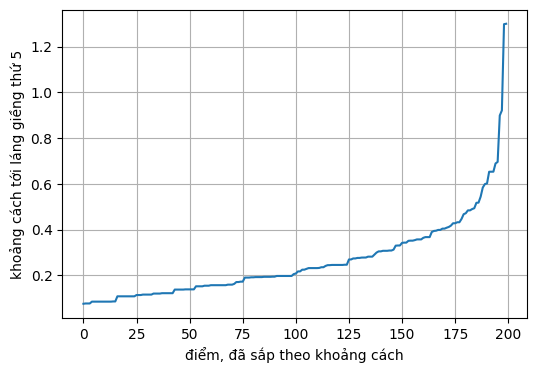

array([0.07633886, 0.07764312, 0.07764312, 0.07764312, 0.08564307,
       0.08564307, 0.08564307, 0.08564307, 0.08564307, 0.08564307,
       0.08564307, 0.08564307, 0.08564307, 0.08564307, 0.08651797,
       0.08651797, 0.10888561, 0.10888561, 0.10888561, 0.10888561,
       0.10888561, 0.10888561, 0.10888561, 0.10888561, 0.10888561,
       0.11450829, 0.11450829, 0.11450829, 0.11646468, 0.11646468,
       0.11646468, 0.11646468, 0.11646468, 0.12091014, 0.12091014,
       0.12091014, 0.12091014, 0.12255989, 0.12255989, 0.12255989,
       0.12255989, 0.12255989, 0.12255989, 0.13834957, 0.13834957,
       0.13834957, 0.13834957, 0.13834957, 0.13925388, 0.13925388,
       0.13925388, 0.13925388, 0.13925388, 0.15267772, 0.15267772,
       0.15267772, 0.15267772, 0.15528624, 0.15528624, 0.15528624,
       0.15753602, 0.15753602, 0.15753602, 0.15753602, 0.15753602,
       0.15753602, 0.15753602, 0.15753602, 0.15990848, 0.15990848,
       0.15990848, 0.16332841, 0.17128613, 0.17128613, 0.17303

In [3]:
mall = pd.read_csv('data/Mall_Customers.csv')
cot = ['Annual Income (k$)', 'Spending Score (1-100)']
X = mall[cot].to_numpy(dtype=float)
X_scaled = StandardScaler().fit_transform(X)

ve_k_distance(X_scaled, min_samples=5)


số cụm: 7
số nhiễu: 35
(array([-1,  0,  1,  2,  3,  4,  5,  6]), array([35, 12,  5,  7, 88, 30, 14,  9]))


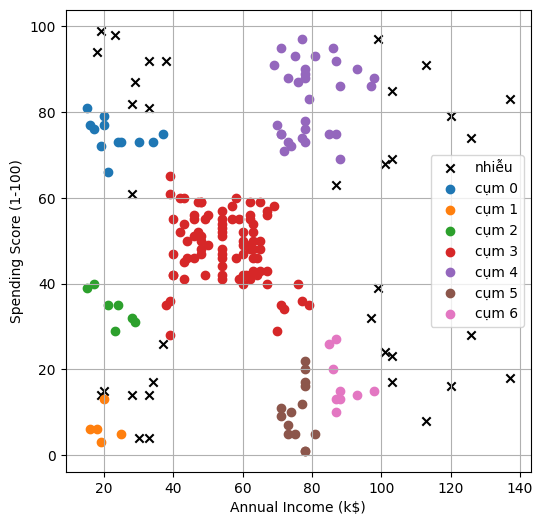

Silhouette, giữ noise: 0.316
Silhouette, bỏ noise: 0.524


In [4]:
# TODO: đọc eps từ đồ thị k-distance
eps = 0.3
min_samples = 5
labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
tom_tat(labels)

plt.figure(figsize=(6, 6))
for cum in np.unique(labels):
    pts = X[labels == cum]
    if cum == -1:
        plt.scatter(pts[:, 0], pts[:, 1], c='black', marker='x', label='nhiễu')
    else:
        plt.scatter(pts[:, 0], pts[:, 1], label=f'cụm {cum}')
plt.xlabel(cot[0])
plt.ylabel(cot[1])
plt.legend()
plt.grid(True)
plt.show()

silhouette_hai_cach(X_scaled, labels)


**Nộp kèm bài 1**

1. `eps` và `min_samples` bạn dùng? Có bao nhiêu cụm, bao nhiêu điểm nhiễu?
2. So với k-Means trên cùng hai cột: điểm khác nhìn thấy trên hình là gì?
3. Silhouette khi giữ noise và khi bỏ noise, số nào cao hơn? Vì sao demo cũng tính lại sau khi bỏ noise?


In [5]:
# Bài 1
# 1.
print("CÂU 1: KẾT QUẢ DBSCAN")
print("eps =", eps)
print("min_samples =", min_samples)

cum = [c for c in np.unique(labels) if c != -1]
n_noise = np.sum(labels == -1)

print("Số cụm:", len(cum))
print("Số điểm nhiễu:", n_noise)


# 2.
print("\nCÂU 2: SO SÁNH VỚI K-MEANS")
print("DBSCAN xác định cụm dựa trên mật độ điểm và có thể phát hiện điểm nhiễu.")
print("K-Means cần chọn trước số cụm K và gán mỗi điểm vào một cụm.")
print("Trên biểu đồ DBSCAN, điểm nhiễu được đánh dấu bằng dấu x màu đen.")


# 3.
print("\nCÂU 3: SO SÁNH SILHOUETTE")

if len(cum) >= 2:
    sil_giu = silhouette_score(X_scaled, labels)
    print("Silhouette giữ noise:", round(sil_giu, 3))

    mask = labels != -1
    labels_clean = labels[mask]
    X_clean = X_scaled[mask]

    if len(np.unique(labels_clean)) >= 2:
        sil_bo = silhouette_score(X_clean, labels_clean)
        print("Silhouette bỏ noise:", round(sil_bo, 3))

        if sil_bo > sil_giu:
            print("Silhouette bỏ noise cao hơn.")
        elif sil_bo < sil_giu:
            print("Silhouette giữ noise cao hơn.")
        else:
            print("Hai giá trị Silhouette bằng nhau.")

        print("Lý do tính lại: điểm noise không thuộc cụm thực sự,")
        print("nên cần đánh giá riêng chất lượng các cụm sau khi loại noise.")
    else:
        print("Không đủ 2 cụm sau khi bỏ noise để tính Silhouette.")
else:
    print("Chưa đủ 2 cụm để tính Silhouette.")


CÂU 1: KẾT QUẢ DBSCAN
eps = 0.3
min_samples = 5
Số cụm: 7
Số điểm nhiễu: 35

CÂU 2: SO SÁNH VỚI K-MEANS
DBSCAN xác định cụm dựa trên mật độ điểm và có thể phát hiện điểm nhiễu.
K-Means cần chọn trước số cụm K và gán mỗi điểm vào một cụm.
Trên biểu đồ DBSCAN, điểm nhiễu được đánh dấu bằng dấu x màu đen.

CÂU 3: SO SÁNH SILHOUETTE
Silhouette giữ noise: 0.316
Silhouette bỏ noise: 0.524
Silhouette bỏ noise cao hơn.
Lý do tính lại: điểm noise không thuộc cụm thực sự,
nên cần đánh giá riêng chất lượng các cụm sau khi loại noise.


---

# Bài 2 — Quốc gia

Cùng file `Country-data.csv`. Bỏ cột `country` khỏi `X`, chuẩn hóa 9 cột số.

Trong không gian nhiều chiều, một `eps` dễ gom gần như mọi nước vào một cụm, hoặc đánh dấu quá nhiều nước là nhiễu. Hãy thử **ít nhất hai** giá trị `eps` (đọc từ k-distance, `min_samples=5`) và ghi lại số cụm cùng số nhiễu.

Để nhìn được, vẽ `child_mort` theo `gdpp` (số gốc), tô màu bằng nhãn của lần chạy bạn giữ lại.


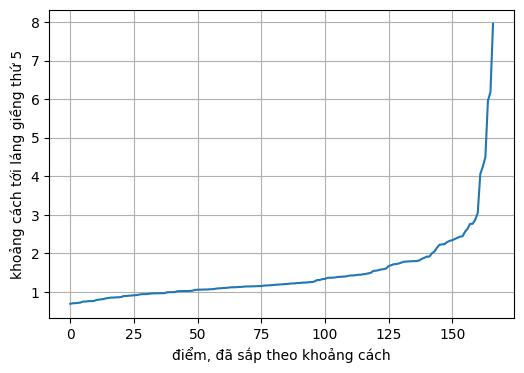

array([0.69386089, 0.70649636, 0.710125  , 0.71705502, 0.72472473,
       0.75035044, 0.75097685, 0.76224146, 0.76224146, 0.76283669,
       0.78492446, 0.80008296, 0.80950113, 0.81615328, 0.83418898,
       0.84374763, 0.8540861 , 0.85433796, 0.86160395, 0.86160395,
       0.86958462, 0.89477821, 0.89515795, 0.90341855, 0.90640002,
       0.91509161, 0.91866263, 0.93083637, 0.94321949, 0.94442841,
       0.94442841, 0.95432138, 0.96279036, 0.96437234, 0.96437234,
       0.96554611, 0.96829791, 0.96855856, 0.99171319, 0.99315359,
       0.99315359, 0.99776886, 1.01848767, 1.02174593, 1.02349259,
       1.02349259, 1.02461021, 1.02683349, 1.03354263, 1.05393707,
       1.05881068, 1.05884856, 1.06292723, 1.06333869, 1.06470317,
       1.07089539, 1.07336542, 1.08416555, 1.09265572, 1.09523494,
       1.10206582, 1.10529465, 1.11087382, 1.12056283, 1.12056283,
       1.12278822, 1.12899228, 1.12997841, 1.1376668 , 1.14240127,
       1.142863  , 1.14477708, 1.14611338, 1.14974814, 1.15264

In [6]:
country = pd.read_csv('data/Country-data.csv')
cot_so = [c for c in country.columns if c != 'country']
X_scaled = StandardScaler().fit_transform(country[cot_so].to_numpy(dtype=float))

ve_k_distance(X_scaled, min_samples=5)


số cụm: 1
số nhiễu: 15
(array([-1,  0]), array([ 15, 152]))


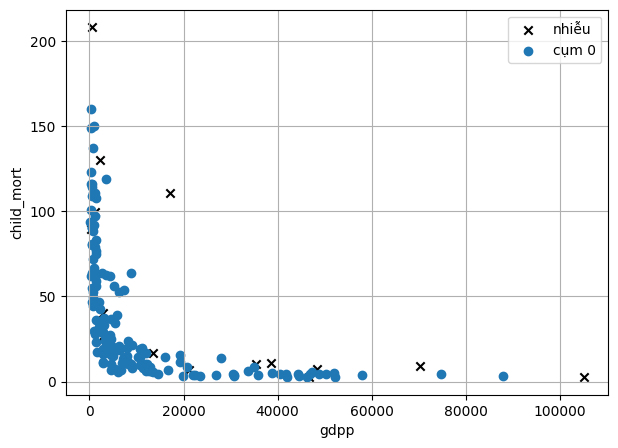

In [7]:
# TODO: thử ít nhất 2 eps, in tom_tat cho mỗi lần
# Giữ lại một eps để vẽ
eps = 2
labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_scaled)
tom_tat(labels)

plt.figure(figsize=(7, 5))
for cum in np.unique(labels):
    pts = country.loc[labels == cum]
    if cum == -1:
        plt.scatter(pts['gdpp'], pts['child_mort'], c='black', marker='x', label='nhiễu')
    else:
        plt.scatter(pts['gdpp'], pts['child_mort'], label=f'cụm {cum}')
plt.xlabel('gdpp')
plt.ylabel('child_mort')
plt.legend()
plt.grid(True)
plt.show()


**Nộp kèm bài 2**

1. Hai giá trị `eps` bạn thử, và số cụm / số nhiễu của mỗi lần?
2. `eps` bạn giữ lại gắn những nước nào vào nhiễu? Kể 3 tên.
3. Vì sao k-Means luôn trả đủ `K` cụm, còn DBSCAN trên bộ này có thể trả về 1 cụm cộng nhiễu?


In [8]:
# Bài 2
# 1.
print("CÂU 1: SO SÁNH HAI GIÁ TRỊ EPS")

for e in [1.5, 2.0]:
    labels_test = DBSCAN(eps=e, min_samples=5).fit_predict(X_scaled)

    cum_test = [c for c in np.unique(labels_test) if c != -1]
    noise_test = np.sum(labels_test == -1)

    print(f"\neps = {e}")
    print("Số cụm:", len(cum_test))
    print("Số điểm nhiễu:", noise_test)


# 2.
print("\nCÂU 2: CÁC QUỐC GIA BỊ XEM LÀ NHIỄU")

noise_countries = country.loc[labels == -1, 'country'].tolist()

print("eps được giữ lại:", eps)
print("Tổng số nước nhiễu:", len(noise_countries))
print("Danh sách nước nhiễu:", noise_countries)
print("Ví dụ 3 nước nhiễu:", noise_countries[:3])


# 3.
print("\nCÂU 3: SO SÁNH K-MEANS VÀ DBSCAN")
print("""
- K-Means yêu cầu chọn trước K nên luôn chia dữ liệu thành K cụm
  khi thuật toán chạy thành công.
- DBSCAN phân cụm dựa trên mật độ điểm, không cần chọn trước số cụm.
- Nếu nhiều quốc gia nằm gần nhau, DBSCAN có thể tạo 1 cụm lớn,
  còn các quốc gia nằm xa vùng mật độ cao sẽ được gắn nhãn -1 (nhiễu).
""")


CÂU 1: SO SÁNH HAI GIÁ TRỊ EPS

eps = 1.5
Số cụm: 1
Số điểm nhiễu: 30

eps = 2.0
Số cụm: 1
Số điểm nhiễu: 15

CÂU 2: CÁC QUỐC GIA BỊ XEM LÀ NHIỄU
eps được giữ lại: 2
Tổng số nước nhiễu: 15
Danh sách nước nhiễu: ['Brunei', 'Equatorial Guinea', 'Haiti', 'Kuwait', 'Lesotho', 'Liberia', 'Luxembourg', 'Malta', 'Micronesia, Fed. Sts.', 'Mongolia', 'Nigeria', 'Qatar', 'Singapore', 'United States', 'Venezuela']
Ví dụ 3 nước nhiễu: ['Brunei', 'Equatorial Guinea', 'Haiti']

CÂU 3: SO SÁNH K-MEANS VÀ DBSCAN

- K-Means yêu cầu chọn trước K nên luôn chia dữ liệu thành K cụm
  khi thuật toán chạy thành công.
- DBSCAN phân cụm dựa trên mật độ điểm, không cần chọn trước số cụm.
- Nếu nhiều quốc gia nằm gần nhau, DBSCAN có thể tạo 1 cụm lớn,
  còn các quốc gia nằm xa vùng mật độ cao sẽ được gắn nhãn -1 (nhiễu).



---

# Bài 3 — Khách sỉ

Cùng 6 cột chi tiêu với bài k-Means. Không đưa `Channel` và `Region` vào `X`. Chuẩn hóa.

Chi tiêu có vài khách rất lớn so với phần còn lại. DBSCAN thường gắn họ là nhiễu (`-1`) thay vì kéo tâm cụm đi, khác k-Means.

Chọn `eps` bằng k-distance (`min_samples=5`). In số cụm, số nhiễu, Silhouette hai cách, và `crosstab` giữa nhãn với `Channel`.


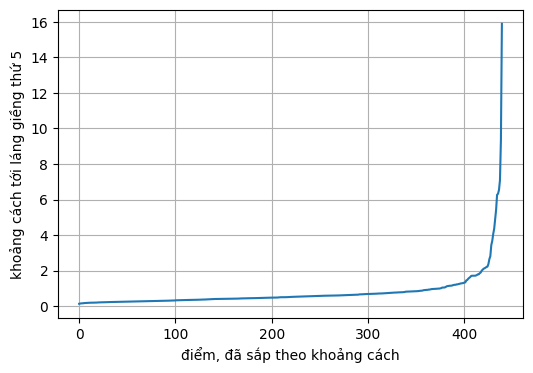

array([ 0.13441662,  0.14585635,  0.15680884,  0.15908042,  0.16118615,
        0.17213295,  0.17623548,  0.1767324 ,  0.17956635,  0.18829292,
        0.19129513,  0.19229513,  0.19283387,  0.19344381,  0.19716451,
        0.19812049,  0.19848513,  0.200307  ,  0.20105381,  0.20760331,
        0.20941286,  0.21276038,  0.21276038,  0.21588432,  0.21616665,
        0.21901006,  0.22051585,  0.22128759,  0.22399036,  0.22416711,
        0.22643411,  0.22998003,  0.23238388,  0.23238388,  0.23358745,
        0.23569132,  0.23780099,  0.23870829,  0.24125176,  0.2429869 ,
        0.24393232,  0.24706877,  0.24741458,  0.2475274 ,  0.24897531,
        0.25121221,  0.25222048,  0.25278696,  0.25321385,  0.25383159,
        0.25706299,  0.257424  ,  0.25981871,  0.26116793,  0.26116793,
        0.26121553,  0.26267533,  0.26454896,  0.26460186,  0.26460186,
        0.26495762,  0.26556821,  0.26879425,  0.27083283,  0.27083343,
        0.27156514,  0.27270039,  0.27463254,  0.2766285 ,  0.27

In [9]:
ws = pd.read_csv('data/Wholesale customers data.csv')
cot_chi = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
X_scaled = StandardScaler().fit_transform(ws[cot_chi].to_numpy(dtype=float))

ve_k_distance(X_scaled, min_samples=5)


In [10]:
eps = 1.5
labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_scaled)
tom_tat(labels)
silhouette_hai_cach(X_scaled, labels)
print(pd.crosstab(labels, ws['Channel'], rownames=['cum'], colnames=['Channel']))


số cụm: 1
số nhiễu: 27
(array([-1,  0]), array([ 27, 413]))
Chưa đủ 2 cụm để tính Silhouette. Đổi eps hoặc min_samples.
Channel    1    2
cum              
-1        12   15
 0       286  127


**Nộp kèm bài 3**

1. `eps` bạn chọn? Bao nhiêu điểm bị coi là nhiễu?
2. Nhãn `-1` có nằm dồn ở một `Channel` không?
3. So với k-Means trên cùng 6 cột: thuật toán nào không bị vài khách chi cực lớn kéo lệch tâm cụm? Giải thích bằng cách mỗi thuật toán tạo cụm.


In [11]:
# Bài 3
# 1.
print("CÂU 1: KẾT QUẢ DBSCAN")
print("eps =", eps)
print("min_samples = 5")
print("Số điểm nhiễu:", np.sum(labels == -1))


# 2.
print("\nCÂU 2: ĐỐI CHIẾU NOISE VỚI CHANNEL")

cross = pd.crosstab(
    labels, ws['Channel'],
    rownames=['Cluster'],
    colnames=['Channel']
)
print(cross)

noise_channel = cross.loc[-1] if -1 in cross.index else None

if noise_channel is not None:
    print("\nSố điểm nhiễu theo Channel:")
    print(noise_channel)

    if noise_channel.max() > noise_channel.min():
        print("Điểm nhiễu xuất hiện nhiều hơn ở Channel",
              noise_channel.idxmax())
    else:
        print("Số điểm nhiễu ở các Channel bằng nhau.")
else:
    print("Không có điểm nhiễu (không có nhãn -1).")


# 3.
print("\nCÂU 3: SO SÁNH DBSCAN VÀ K-MEANS")
print("""
DBSCAN ít bị ảnh hưởng bởi vài khách có mức chi tiêu cực lớn
vì phân cụm dựa trên mật độ điểm; khách nằm xa vùng đông có thể
bị gắn nhãn nhiễu (-1).

K-Means phân cụm dựa trên khoảng cách đến tâm cụm và cập nhật tâm
bằng trung bình các điểm trong cụm. Vì vậy, khách có giá trị chi tiêu
rất lớn có thể kéo tâm cụm về phía họ.
""")


CÂU 1: KẾT QUẢ DBSCAN
eps = 1.5
min_samples = 5
Số điểm nhiễu: 27

CÂU 2: ĐỐI CHIẾU NOISE VỚI CHANNEL
Channel    1    2
Cluster          
-1        12   15
 0       286  127

Số điểm nhiễu theo Channel:
Channel
1    12
2    15
Name: -1, dtype: int64
Điểm nhiễu xuất hiện nhiều hơn ở Channel 2

CÂU 3: SO SÁNH DBSCAN VÀ K-MEANS

DBSCAN ít bị ảnh hưởng bởi vài khách có mức chi tiêu cực lớn
vì phân cụm dựa trên mật độ điểm; khách nằm xa vùng đông có thể
bị gắn nhãn nhiễu (-1).

K-Means phân cụm dựa trên khoảng cách đến tâm cụm và cập nhật tâm
bằng trung bình các điểm trong cụm. Vì vậy, khách có giá trị chi tiêu
rất lớn có thể kéo tâm cụm về phía họ.

